# 01. EDA та підготовка даних

Ноутбук робить три речі: досліджує VisDrone-VID, будує спільний датасет для всіх моделей і перевіряє його візуально. Усі подальші ноутбуки читають готову папку `prepared/`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.cluster import KMeans

sys.path.insert(0, ".")
import common as c

c.set_seed()
DATA, OUT, IMG = Path("../data"), Path("../prepared"), Path("../images")
IMG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, name):
    fig.savefig(IMG / name, bbox_inches="tight", dpi=130)
    plt.show()

## 1. Завантаження анотацій

In [2]:
def load(split):
    coco = json.load(open(DATA / split / "annotations_coco.json"))
    images = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    ann = pd.DataFrame(coco["annotations"])
    ann[["x", "y", "w", "h"]] = pd.DataFrame(ann["bbox"].tolist(), index=ann.index)
    ann = ann.merge(images[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    ann["scale"] = c.LONG_SIDE / ann[["width", "height"]].max(axis=1)
    ann["side"] = np.sqrt(ann.w * ann.h)
    ann["side960"] = ann.side * ann.scale
    return images, ann


tr_images, tr = load("train")
va_images, va = load("val")
test = pd.read_csv(DATA / "test_images.csv")


def summary(images, ann):
    obj = ann[ann.iscrowd == 0]
    return {
        "послідовностей": images.video.nunique(),
        "кадрів": len(images),
        "об'єктів": len(obj),
        "ignore-регіонів": int((ann.iscrowd == 1).sum()),
        "об'єктів на кадр": round(len(obj) / len(images), 1),
    }


pd.DataFrame({"train": summary(tr_images, tr), "val": summary(va_images, va)})

,train,val
послідовностей,56.0,7.0
кадрів,24201.0,2846.0
об'єктів,1105516.0,114132.0
ignore-регіонів,510744.0,31960.0
об'єктів на кадр,45.7,40.1


Train містить 56 послідовностей і 1,1 млн об'єктів (≈46 на кадр), а ще 0,5 млн ignore-регіонів. Val має лише 7 послідовностей, тому оцінка на ньому шумна, особливо для рідких класів.

## 2. Баланс класів

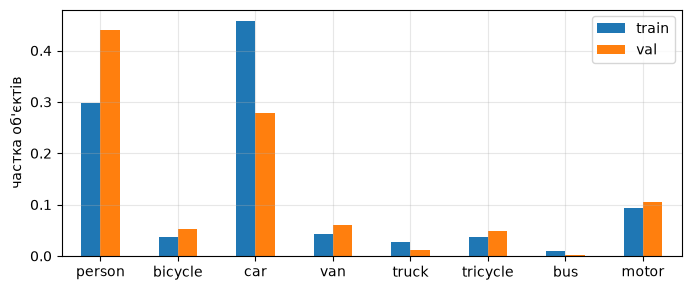

,person,bicycle,car,van,truck,tricycle,bus,motor
train,0.297,0.036,0.457,0.042,0.028,0.037,0.009,0.093
val,0.441,0.053,0.279,0.060,0.012,0.048,0.002,0.105


In [3]:
names = c.CLASSES
share = pd.DataFrame({
    s: a[a.iscrowd == 0].category_id.value_counts(normalize=True).sort_index()
    for s, a in (("train", tr), ("val", va))
})
share.index = names
fig, ax = plt.subplots(figsize=(8, 3.2))
share.plot.bar(ax=ax, rot=0)
ax.set_ylabel("частка об'єктів")
save(fig, "eda_classes.png")
share.round(3).T

У train домінують car (46%) і person (30%), а bus лише 0,9%. У val розподіл інший: person 44%, car 28%, bus 0,2%. Тому AP окремих рідкісних класів на val нестабільний, і основним показником лишається mAP за всіма класами.

## 3. Розміри об'єктів

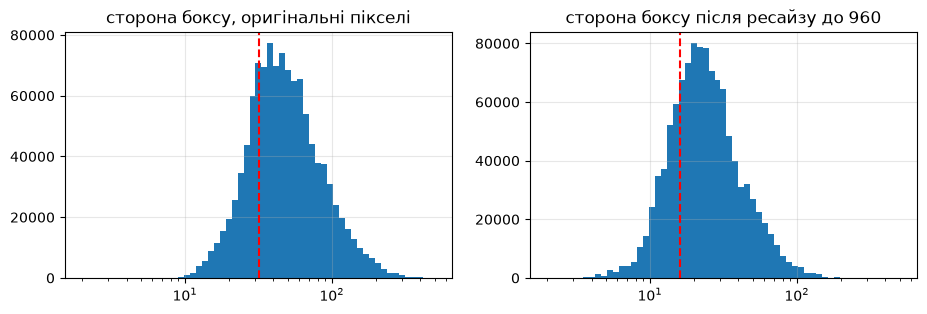

,medium,small,large
"частка (COCO, оригінал)",0.635,0.249,0.116


side960,"(0.0, 8.0]","(8.0, 16.0]","(16.0, 32.0]","(32.0, 64.0]","(64.0, inf]"
частка після ресайзу,0.017,0.223,0.496,0.218,0.047


,0.25,0.50,0.75
category_id,,,
bicycle,14.5,18.9,25.6
bus,31.6,52.1,81.6
car,18.8,26.9,39.6
motor,14.4,19.2,25.6
person,13.5,18.4,24.7
tricycle,20.1,28.8,39.9
truck,23.8,37.0,55.2
van,19.7,25.4,38.7


In [4]:
obj = tr[tr.iscrowd == 0]
bins = np.geomspace(2, 500, 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(obj.side, bins=bins)
axes[0].axvline(32, color="r", ls="--")
axes[0].set_title("сторона боксу, оригінальні пікселі")
axes[1].hist(obj.side960, bins=bins)
axes[1].axvline(16, color="r", ls="--")
axes[1].set_title("сторона боксу після ресайзу до 960")
for ax in axes:
    ax.set_xscale("log")
save(fig, "eda_sizes.png")

by_area = pd.cut(obj.w * obj.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
buckets = pd.cut(obj.side960, [0, 8, 16, 32, 64, np.inf]).value_counts(normalize=True).sort_index()
per_class = obj.groupby(obj.category_id.map(lambda i: names[i - 1])).side960.quantile([0.25, 0.5, 0.75]).unstack()
display(by_area.value_counts(normalize=True).round(3).to_frame("частка (COCO, оригінал)").T)
display(buckets.round(3).to_frame("частка після ресайзу").T)
per_class.round(1)

За COCO-порогами 25% об'єктів small (сторона менша за 32 px у оригіналі). Після ресайзу до 960 px 24% боксів стають меншими за 16 px, а ще 50% лежать у діапазоні 16-32 px. Медіанна сторона: person 18 px, bicycle і motor 19, car 27, bus 52. Висновок: стандартні anchors torchvision (від 32 px) не підходять, потрібні дрібніші, а роздільність 1280 варто перевірити окремим експериментом.

## 4. Щільність сцен та ignore-регіони

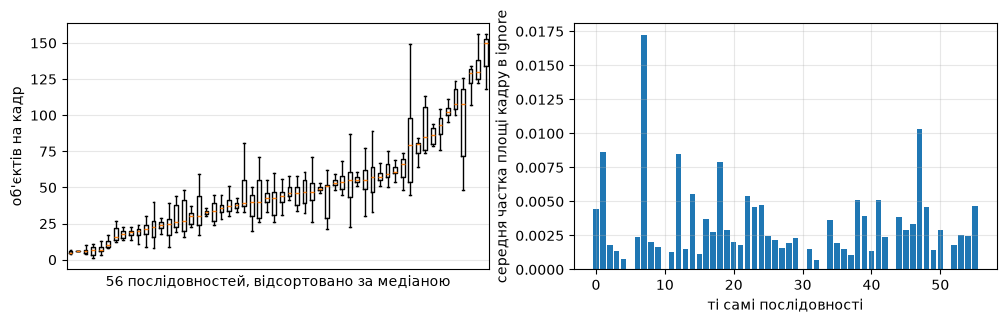

{'count': 24198.0, 'mean': 45.7, 'std': 31.6, 'min': 1.0, '25%': 22.0, '50%': 43.0, '75%': 57.0, 'max': 180.0}


,,train,val,test
width,height,,,
1344,756,11,2,7
1360,765,1,0,0
1904,1071,30,2,0
1920,1080,1,0,11
2688,1512,11,1,0
2720,1530,2,1,0
3840,2160,0,1,0
680,382,0,0,3
960,540,0,0,5


In [5]:
dens = obj.groupby(["video", "frame_id"]).size().rename("n").reset_index()
order = dens.groupby("video").n.median().sort_values().index
ig = tr[tr.iscrowd == 1]
ig_share = (ig.w * ig.h / (ig.width * ig.height)).groupby(ig.video).sum().clip(upper=1)
ig_share = (ig_share / tr_images.groupby("video").size()).reindex(order).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].boxplot([dens[dens.video == v].n for v in order], showfliers=False)
axes[0].set_xticks([])
axes[0].set_xlabel("56 послідовностей, відсортовано за медіаною")
axes[0].set_ylabel("об'єктів на кадр")
axes[1].bar(range(len(order)), ig_share.values)
axes[1].set_xlabel("ті самі послідовності")
axes[1].set_ylabel("середня частка площі кадру в ignore")
save(fig, "eda_density.png")

res = pd.concat({
    "train": tr_images.groupby(["width", "height"]).video.nunique(),
    "val": va_images.groupby(["width", "height"]).video.nunique(),
    "test": test.groupby(["width", "height"]).clip.nunique(),
}, axis=1).fillna(0).astype(int)
print(dens.n.describe().round(1).to_dict())
res

Медіана 43 об'єкти на кадр, верхній квартиль 57, максимум 180. Медіана за клипом коливається від 5 до приблизно 130, тобто сцени дуже різнорідні. Тому ліміт детекцій на кадр у NMS-моделях має бути не менший за 300, а для RT-DETR кількість запитів не менша за 300. Ignore-регіони займають лише 0,1-1,7% площі кадру, але їх у середньому понад 20 на кадр, тому маскування має сенс. У test є клипи 680x382 і 960x540, яких немає в train, тож масштаб об'єктів на тесті відрізняється, і multi-scale аугментація виправдана.

## 5. Крок прорідження кадрів

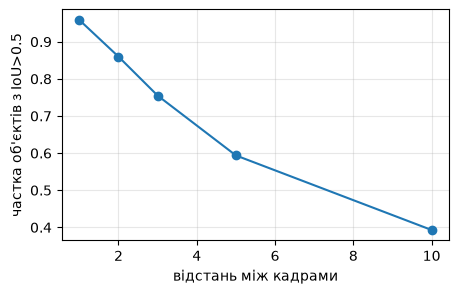

,медіана IoU,частка IoU>0.5
1,0.897,0.959
2,0.810,0.860
3,0.731,0.755
5,0.597,0.594
10,0.357,0.393


In [6]:
o = obj[["video", "track_id", "frame_id", "x", "y", "w", "h"]]


def lag_iou(lag):
    nxt = o.assign(frame_id=o.frame_id + lag)
    m = o.merge(nxt, on=["video", "track_id", "frame_id"], suffixes=("", "_p"))
    iw = (np.minimum(m.x + m.w, m.x_p + m.w_p) - np.maximum(m.x, m.x_p)).clip(lower=0)
    ih = (np.minimum(m.y + m.h, m.y_p + m.h_p) - np.maximum(m.y, m.y_p)).clip(lower=0)
    inter = iw * ih
    return inter / (m.w * m.h + m.w_p * m.h_p - inter)


lags = (1, 2, 3, 5, 10)
rows = {}
for lag in lags:
    iou = lag_iou(lag)
    rows[lag] = {"медіана IoU": iou.median(), "частка IoU>0.5": (iou > 0.5).mean()}
stride = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(stride.index, stride["частка IoU>0.5"], marker="o")
ax.set_xlabel("відстань між кадрами")
ax.set_ylabel("частка об'єктів з IoU>0.5")
save(fig, "eda_stride.png")
stride.round(3)

Для того самого об'єкта IoU між кадрами t і t+k такий: при k=1 частка IoU>0.5 дорівнює 96%, при k=3 76%, при k=5 59%, при k=10 39%. Сусідні кадри майже дублікати, а при кроці 3 бокси ще перекриваються (медіана IoU 0,73), тож це хороший баланс між різноманітністю і обсягом. Для val беремо крок 2, щоб оцінка була стабільнішою.

## 6. Форма боксів і кластеризація

In [7]:
wh = np.stack([obj.w * obj.scale, obj.h * obj.scale], axis=1)
rng = np.random.default_rng(c.SEED)
sample = wh[rng.choice(len(wh), 200_000, replace=False)]
km = KMeans(9, n_init=10, random_state=c.SEED).fit(sample)
anchors = km.cluster_centers_[np.argsort(km.cluster_centers_.prod(axis=1))].round(1)
OUT.mkdir(exist_ok=True)
json.dump(anchors.tolist(), open(OUT / "anchors_960.json", "w"))
ratio = (obj.h / obj.w).groupby(obj.category_id.map(lambda i: names[i - 1])).median().round(2)
display(pd.DataFrame(anchors, columns=["w", "h"]).T)
ratio.to_frame("медіана h/w").T

,0,1,2,3,4,5,6,7,8
w,12.4,16.4,31.7,27.2,56.0,46.8,90.8,86.1,160.1
h,14.6,26.5,20.3,41.1,29.9,64.6,46.3,101.3,88.9


category_id,bicycle,bus,car,motor,person,tricycle,truck,van
медіана h/w,1.06,0.97,0.8,1.24,2.0,0.94,0.93,0.9


Дев'ять центрів k-means у пікселях 960-кадру: від 12x15 до 160x89. Найменші центри відповідають людям і мотоциклам. Співвідношення h/w: person 2,0, motor 1,24, car 0,8, решта близько 1, тому aspect ratios (0.5, 1, 2) покривають розподіл. Ці центри використаємо як основу для anchors у RetinaNet.

## 7. Візуальна перевірка розмітки

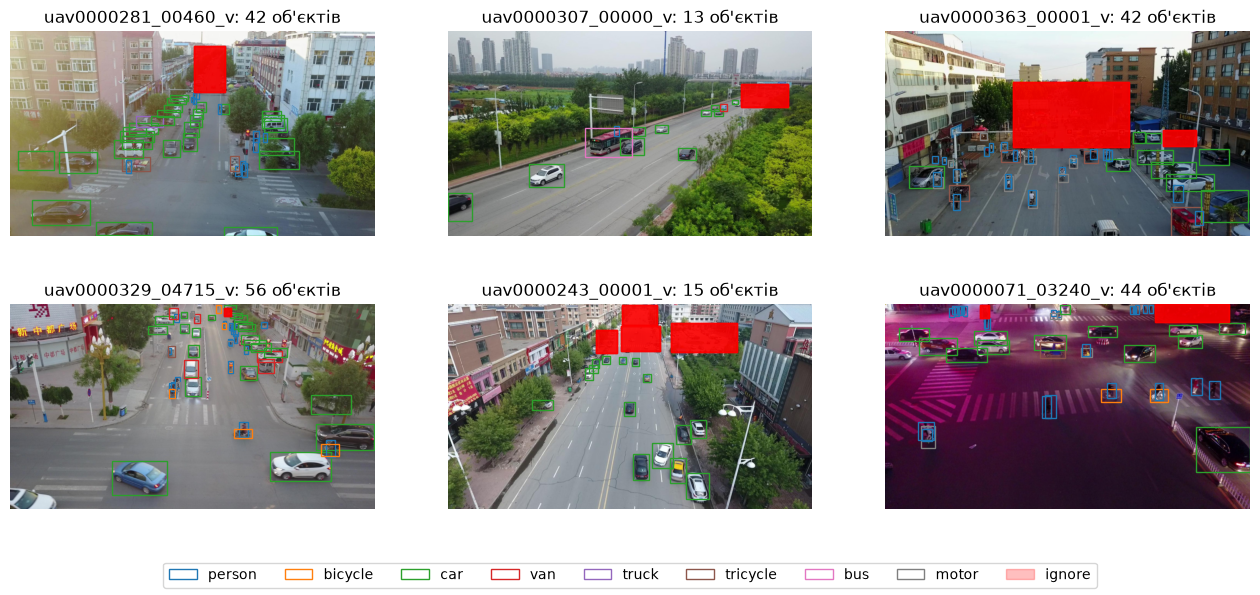

In [8]:
rng = np.random.default_rng(c.SEED)
clips = rng.choice(sorted(tr_images.video.unique()), 6, replace=False)
colors = plt.cm.tab10(np.arange(8))
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for ax, clip in zip(axes.ravel(), clips):
    im = tr_images[tr_images.video == clip].sample(1, random_state=c.SEED).iloc[0]
    arr, sx, sy = c.load_resized(DATA / "train" / im.file_name)
    ax.imshow(arr)
    rows = tr[tr.image_id == im.image_id]
    for r in rows.itertuples():
        x, y, w, h = r.x * sx, r.y * sy, r.w * sx, r.h * sy
        if r.iscrowd:
            ax.add_patch(Rectangle((x, y), w, h, color="red", alpha=0.25))
        else:
            ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=colors[r.category_id - 1], lw=1))
    ax.set_title(f"{clip}: {int((rows.iscrowd == 0).sum())} об'єктів")
    ax.axis("off")
handles = [Rectangle((0, 0), 1, 1, fill=False, edgecolor=colors[i]) for i in range(8)]
fig.legend(handles + [Rectangle((0, 0), 1, 1, color="red", alpha=0.25)], names + ["ignore"], ncol=9, loc="lower center")
save(fig, "eda_gt_samples.png")

Бокси лежать на об'єктах, а ignore-регіони (червоні) покривають ділянки без розмітки.

## 8. Побудова спільного датасету

Правила, однакові для всіх моделей: train кожен 3-й кадр, val кожен 2-й, довга сторона 960 px, ignore-зони замальовані сірим лише в train. Для кожного кадру зберігаються JPEG, YOLO-розмітка та COCO-розмітка в координатах зменшеного кадру з масштабами `scale_x`, `scale_y`. Для val додатково створюється `annotations_eval.json` в оригінальних координатах: прогнози повертаються в них через `common.to_original`, тому AP_small рахується за тими самими порогами площі, що й у змаганні. Тест тільки зменшується, масштаби лежать у `scales.csv`.

In [9]:
CATEGORIES = [{"id": i + 1, "name": n} for i, n in enumerate(c.CLASSES)]


def box_ann(a, sx, sy):
    x, y, w, h = c.scale_boxes(a["bbox"], sx, sy)[0]
    return {"id": a["id"], "image_id": a["image_id"], "category_id": a["category_id"],
            "bbox": [round(x, 2), round(y, 2), round(w, 2), round(h, 2)],
            "area": round(w * h, 2), "iscrowd": a["iscrowd"]}


def build_split(split, stride, mask):
    images, objects, ignore = c.load_coco(DATA / split / "annotations_coco.json")
    frames = c.select_frames(images, stride)
    root = OUT / split
    coco_images, coco_anns, eval_images, eval_anns = [], [], [], []
    for im in frames:
        clip, name = im["video"], Path(im["file_name"]).stem
        crowd = ignore.get(im["id"], [])
        boxes = [a["bbox"] for a in crowd] if mask else ()
        arr, sx, sy = c.load_resized(DATA / split / im["file_name"], ignore_boxes=boxes)
        img_path = root / "images" / clip / f"{name}.jpg"
        lbl_path = root / "labels" / clip / f"{name}.txt"
        for p in (img_path, lbl_path):
            p.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(arr).save(img_path, quality=95)
        lbl_path.write_text("\n".join(c.to_yolo(objects.get(im["id"], []), im["width"], im["height"])))
        coco_images.append({"id": im["id"], "file_name": f"images/{clip}/{name}.jpg",
                            "width": arr.shape[1], "height": arr.shape[0], "video": clip,
                            "frame_id": im["frame_id"], "scale_x": sx, "scale_y": sy})
        eval_images.append({k: im[k] for k in ("id", "file_name", "width", "height", "video", "frame_id")})
        for a in objects.get(im["id"], []) + crowd:
            coco_anns.append(box_ann(a, sx, sy))
            eval_anns.append({k: a[k] for k in ("id", "image_id", "category_id", "bbox", "area", "iscrowd")})
    (root / "annotations_coco.json").write_text(
        json.dumps({"images": coco_images, "annotations": coco_anns, "categories": CATEGORIES}))
    if split == "val":
        (root / "annotations_eval.json").write_text(
            json.dumps({"images": eval_images, "annotations": eval_anns, "categories": CATEGORIES}))


def build_test():
    rows = []
    for r in test.itertuples():
        arr, sx, sy = c.load_resized(DATA / r.file_name)
        dst = OUT / "test" / "images" / r.clip / Path(r.file_name).name
        dst.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(arr).save(dst, quality=95)
        rows.append((r.image_id, r.clip, r.frame, r.width, r.height, arr.shape[1], arr.shape[0], sx, sy))
    cols = ["image_id", "clip", "frame", "width", "height", "new_width", "new_height", "scale_x", "scale_y"]
    pd.DataFrame(rows, columns=cols).to_csv(OUT / "test" / "scales.csv", index=False)


if not (OUT / "train" / "annotations_coco.json").exists():
    build_split("train", c.TRAIN_STRIDE, mask=True)
if not (OUT / "val" / "annotations_coco.json").exists():
    build_split("val", c.VAL_STRIDE, mask=False)
if not (OUT / "test" / "scales.csv").exists():
    build_test()
(OUT / "data.yaml").write_text(
    f"train: train/images\nval: val/images\nnc: {len(c.CLASSES)}\nnames: {json.dumps(c.CLASSES)}\n")

122

## 9. Перевірка готового датасету

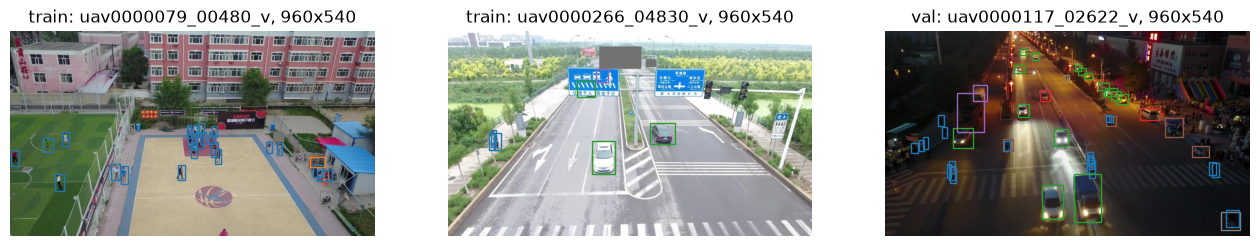

{'кадрів': {'train': 8090, 'val': 1425, 'test': 3811}, 'розмір, ГБ': {'test': 0.62, 'train': 1.66, 'val': 0.29}}


In [10]:
def show(ax, split, k):
    meta = json.load(open(OUT / split / "annotations_coco.json"))["images"][k]
    img = np.asarray(Image.open(OUT / split / meta["file_name"]))
    ax.imshow(img)
    label = OUT / split / "labels" / meta["video"] / (Path(meta["file_name"]).stem + ".txt")
    h, w = img.shape[:2]
    for line in label.read_text().splitlines():
        cl, cx, cy, bw, bh = line.split()
        ax.add_patch(Rectangle(((float(cx) - float(bw) / 2) * w, (float(cy) - float(bh) / 2) * h),
                               float(bw) * w, float(bh) * h, fill=False,
                               edgecolor=colors[int(cl)], lw=1))
    ax.set_title(f"{split}: {meta['video']}, {w}x{h}")
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
show(axes[0], "train", 700)
show(axes[1], "train", 4000)
show(axes[2], "val", 300)
save(fig, "eda_prepared_check.png")

sizes = {p.name: sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9 for p in OUT.iterdir() if p.is_dir()}
counts = {s: len(list((OUT / s / "images").rglob("*.jpg"))) for s in ("train", "val", "test")}
print({"кадрів": counts, "розмір, ГБ": {k: round(v, 2) for k, v in sizes.items()}})

Готові 8090 train-кадрів, 1425 val-кадрів і 3811 test-кадрів (разом 2,6 ГБ). Сірі прямокутники на train-кадрах це замальовані ignore-зони, у val кадри не змінюються.